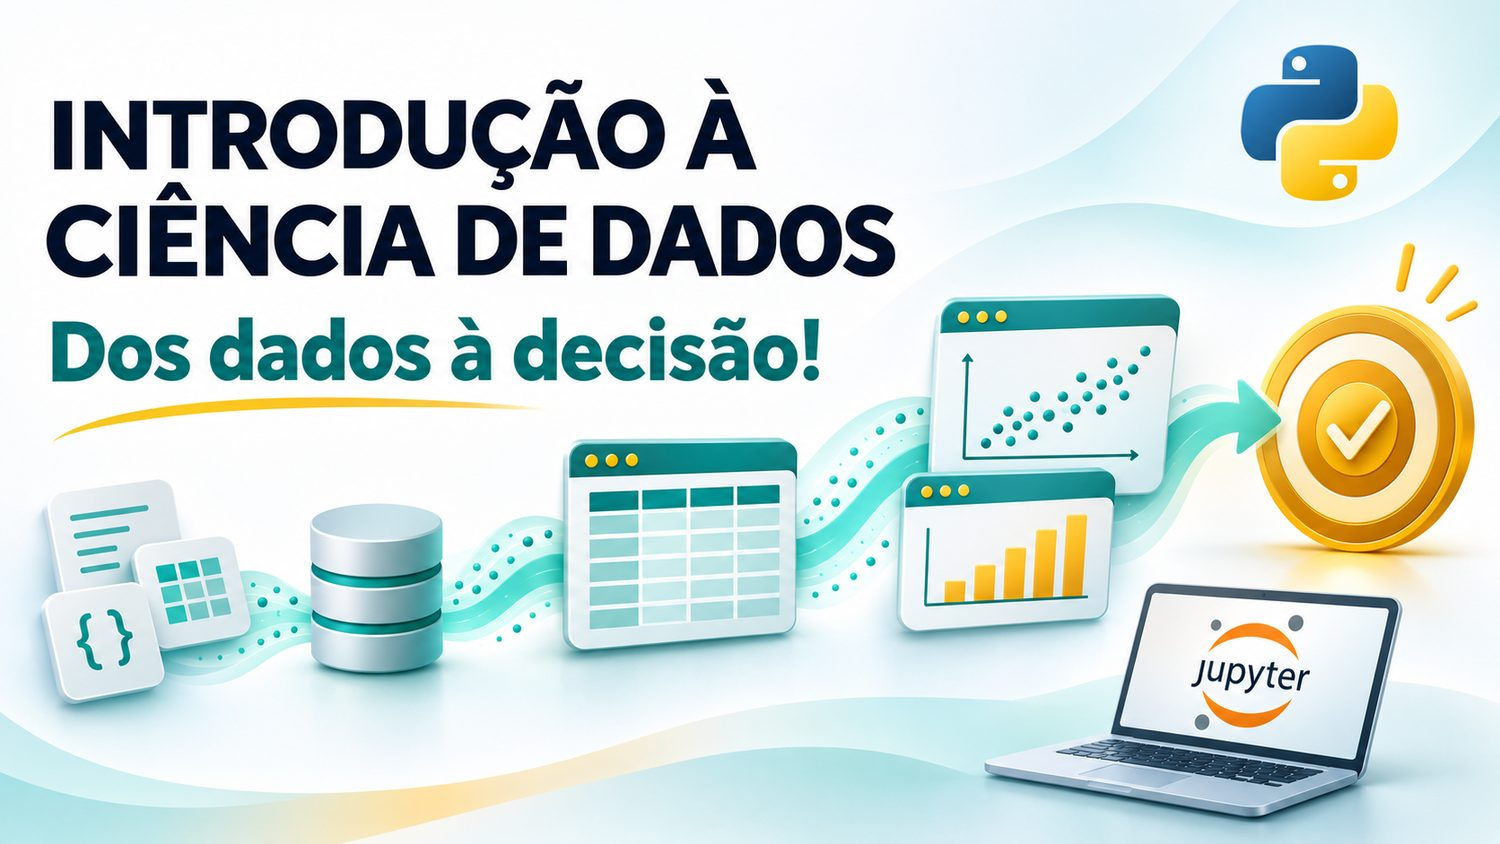

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_supervisionados/03_KNN_Regressao.ipynb)

# Capítulo 3 – K vizinhos mais próximos: regressão

A mesma ideia do capítulo anterior serve para prever números. Em vez de os vizinhos **votarem** numa classe, faz-se a **média** dos seus valores. Este capítulo implementa a versão de regressão, com média simples e com média ponderada, e mostra os dois limites do método que mais importa conhecer: não sabe extrapolar e perde-se quando há muitos atributos.

> **Objetivos:** adaptar o KNN à previsão de valores numéricos; implementar a média simples e a média ponderada pelo inverso da distância; ver o efeito de k na curva de previsão; escolher k pelo erro de validação; comparar com uma regressão linear através dos resíduos; reconhecer o problema da extrapolação e a maldição da dimensionalidade.

**Pré-requisitos:** capítulos 1 e 2. A sintaxe do scikit-learn está em [Scikit-Learn: fundamentos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_03_ScikitLearn_Fundamentos.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


## De votar a fazer a média

Queremos prever `tempo_min`, o tempo que uma entrega demora. Começamos com um só atributo, a distância, para podermos desenhar a previsão como uma curva. Para a relação ficar limpa, olhamos apenas para as entregas de mota, fora das horas de ponta e sem chuva.

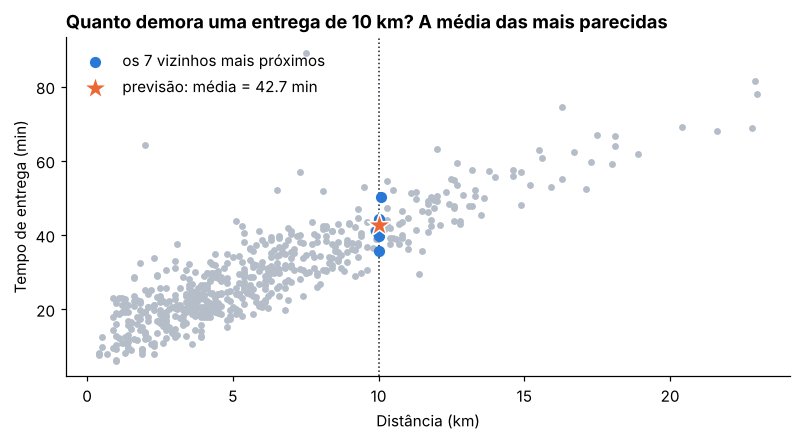

In [3]:
from sklearn.model_selection import train_test_split

treino, resto = train_test_split(entregas, test_size=0.4, random_state=0)
validacao, teste = train_test_split(resto, test_size=0.5, random_state=0)

calmas = treino[(treino["veiculo"] == "mota") & ~treino["chuva"] & treino["hora"].between(9.5, 17) & (treino["tempo_min"] < 90)]
x, t = calmas["distancia_km"].to_numpy(), calmas["tempo_min"].to_numpy()
nova = 10.0
proximos = np.argsort(np.abs(x - nova))[:7]

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(x, t, s=12, color=CINZA)
ax.scatter(x[proximos], t[proximos], s=40, color=AZUL, zorder=3, label="os 7 vizinhos mais próximos")
ax.axvline(nova, color=TINTA, ls=":", lw=1)
ax.scatter([nova], [t[proximos].mean()], marker="*", s=260, color=LARANJA, edgecolor="white", zorder=4, label=f"previsão: média = {t[proximos].mean():.1f} min")
ax.set_xlabel("Distância (km)")
ax.set_ylabel("Tempo de entrega (min)")
ax.set_title(f"Quanto demora uma entrega de {nova:.0f} km? A média das mais parecidas")
ax.legend(frameon=False, loc="upper left")
plt.show()

Os passos 1 e 2 são os mesmos do capítulo anterior: medir distâncias e ficar com os k mais próximos. Só muda o passo 3.

| | Classificação | Regressão |
| --- | --- | --- |
| Passo 3 | Votação: a classe mais frequente | Média dos valores dos vizinhos |
| A previsão é | Uma categoria | Um número |
| Avalia-se com | Exatidão, precisão, sensibilidade, F1 | MAE, RMSE, R² |

## Implementar de raiz

In [4]:
def knn_regressao_um(x_novo, X, y, k, ponderada=False):
    """Prevê um valor numérico: a média (simples ou ponderada) dos k vizinhos mais próximos."""
    distancias = np.sqrt(((X - x_novo) ** 2).sum(axis=1))
    vizinhos = np.argsort(distancias)[:k]
    if not ponderada:
        return y[vizinhos].mean()
    pesos = 1 / (distancias[vizinhos] + 1e-9)             # o vizinho mais próximo pesa mais
    return (pesos * y[vizinhos]).sum() / pesos.sum()


def knn_regressao(X_novos, X, y, k, ponderada=False):
    return np.array([knn_regressao_um(x_novo, X, y, k, ponderada) for x_novo in X_novos])


X1 = x.reshape(-1, 1)                                     # uma coluna: o scikit-learn e a nossa função esperam uma tabela
print(f"Previsão para {nova:.0f} km, k = 7:  média simples {knn_regressao_um(np.array([nova]), X1, t, 7):.1f} min"
      f"  |  média ponderada {knn_regressao_um(np.array([nova]), X1, t, 7, ponderada=True):.1f} min")

Previsão para 10 km, k = 7:  média simples 42.7 min  |  média ponderada 41.6 min


### Média simples e média ponderada

Na **média simples**, os k vizinhos contam todos o mesmo. Na **média ponderada pelo inverso da distância**, cada vizinho conta na proporção de 1 ÷ distância: um vizinho a 0,1 de distância pesa dez vezes mais do que um a 1.

| Vizinho | Distância | Tempo | Peso (1 ÷ distância) |
| --- | --- | --- | --- |
| 1.º | 0,1 | 30 min | 10 |
| 2.º | 0,5 | 36 min | 2 |
| 3.º | 1,0 | 45 min | 1 |

- Média simples: (30 + 36 + 45) ÷ 3 = **37,0 min**
- Média ponderada: (10 × 30 + 2 × 36 + 1 × 45) ÷ 13 = **32,1 min**

A soma do `1e-9` no código evita uma divisão por zero quando um vizinho coincide exatamente com o ponto novo.

Confirmamos que a nossa implementação dá o mesmo que a do scikit-learn, em quase todos os casos. Usamos dois atributos normalizados (a distância e a hora) e todas as entregas de treino.

In [5]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

dois = ["distancia_km", "hora"]
escala = StandardScaler().fit(treino[dois])
A, B, alvo = escala.transform(treino[dois]), escala.transform(validacao[dois]), treino["tempo_min"].to_numpy()
for ponderada, pesos in [(False, "uniform"), (True, "distance")]:
    nosso = knn_regressao(B, A, alvo, 7, ponderada)
    oficial = KNeighborsRegressor(n_neighbors=7, weights=pesos).fit(A, alvo).predict(B)
    print(f"weights='{pesos}': previsões iguais em {np.isclose(nosso, oficial, atol=1e-6).mean():.1%} das {len(B)} entregas de validação")

weights='uniform': previsões iguais em 98.4% das 800 entregas de validação
weights='distance': previsões iguais em 98.4% das 800 entregas de validação


> Quando dois vizinhos estão **exatamente** à mesma distância e só há lugar para um, é preciso desempatar, e cada implementação fá-lo à sua maneira. Com atributos arredondados (a distância tem uma casa decimal) os empates são frequentes, e duas implementações corretas podem dar previsões ligeiramente diferentes.

## O efeito de k

Prevendo para todas as distâncias, obtemos a **curva de previsão** do modelo.

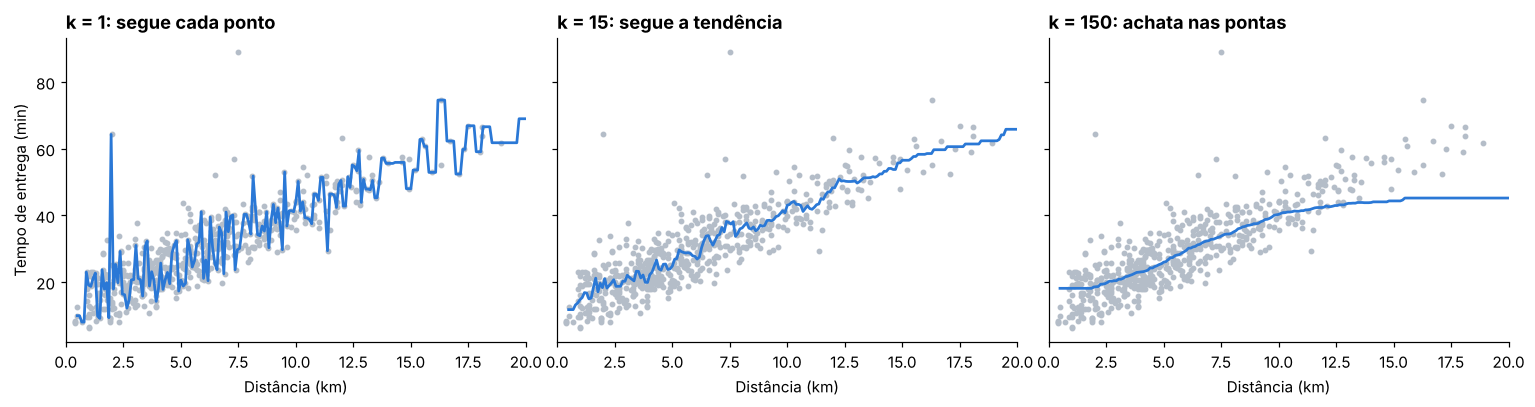

In [6]:
pontos_novos = np.linspace(0.5, 20, 200).reshape(-1, 1)
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, k in zip(eixos, [1, 15, 150]):
    ax.scatter(x, t, s=8, color=CINZA)
    ax.plot(pontos_novos, KNeighborsRegressor(n_neighbors=k).fit(X1, t).predict(pontos_novos), color=AZUL, lw=1.8)
    ax.set_xlabel("Distância (km)")
    ax.set_xlim(0, 20)
    ax.set_title({1: "k = 1: segue cada ponto", 15: "k = 15: segue a tendência", 150: "k = 150: achata nas pontas"}[k])
eixos[0].set_ylabel("Tempo de entrega (min)")
plt.tight_layout()
plt.show()

- Com **k = 1**, a curva passa por todos os pontos de treino e salta de um para outro. Está a reproduzir o ruído.
- Com **k = 15**, a média alisa o ruído e fica a tendência.
- Com **k = 150**, a média junta entregas demasiado diferentes. Nas pontas, onde há poucos dados, os «vizinhos» são sempre os mesmos e a curva fica horizontal.

A previsão de um KNN é sempre uma curva **em degraus**: muda de valor quando muda o conjunto de vizinhos. Com a média ponderada os degraus ficam mais suaves, mas a curva passa a ser atraída por cada ponto individual.

## Duas dimensões: o KNN encontra as horas de ponta

No capítulo 1, os resíduos da regressão linear mostraram que ela subestimava o tempo nas horas de ponta. Vejamos o que faz um KNN com a distância e a hora, usando agora todas as entregas.

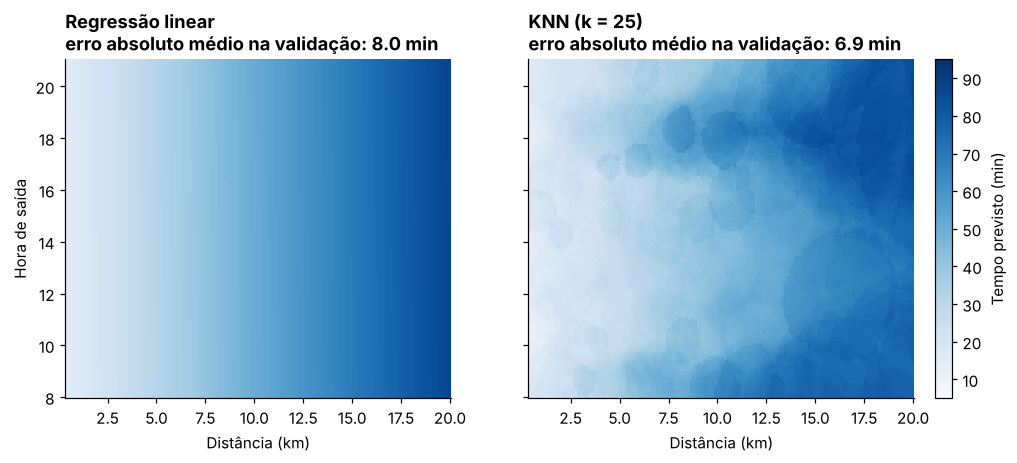

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

grelha_x, grelha_y = np.meshgrid(np.linspace(0.4, 20, 160), np.linspace(8, 21, 160))
grelha = pd.DataFrame({"distancia_km": grelha_x.ravel(), "hora": grelha_y.ravel()})
modelos = {"Regressão linear": LinearRegression(), "KNN (k = 25)": make_pipeline(StandardScaler(), KNeighborsRegressor(25))}

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nome, modelo) in zip(eixos, modelos.items()):
    modelo.fit(treino[dois], treino["tempo_min"])
    mapa = ax.pcolormesh(grelha_x, grelha_y, modelo.predict(grelha).reshape(grelha_x.shape), cmap="Blues", vmin=5, vmax=95, shading="auto")
    erro = np.abs(validacao["tempo_min"] - modelo.predict(validacao[dois])).mean()
    ax.set_title(f"{nome}\nerro absoluto médio na validação: {erro:.1f} min")
    ax.set_xlabel("Distância (km)")
eixos[0].set_ylabel("Hora de saída")
fig.colorbar(mapa, ax=eixos, label="Tempo previsto (min)", pad=0.02)
plt.show()

Cada mapa mostra o tempo previsto para cada combinação de distância e hora.

A regressão linear só consegue produzir um **plano inclinado**: o tempo cresce com a distância e muda ligeiramente com a hora, sempre ao mesmo ritmo. No mapa do KNN notam-se duas **faixas horizontais mais escuras**, de manhã e ao fim da tarde, onde a mesma distância demora mais. Ninguém lhe falou em horas de ponta: encontrou-as porque as entregas vizinhas, a essas horas, demoraram mais.

É a vantagem de um modelo que não assume nenhuma forma para a relação. A desvantagem é a zona da direita do mapa: há poucas entregas de longa distância e as previsões ficam irregulares.

## Escolher k

Como no capítulo anterior, k escolhe-se pelo erro na validação. A métrica é agora o erro absoluto médio (MAE).

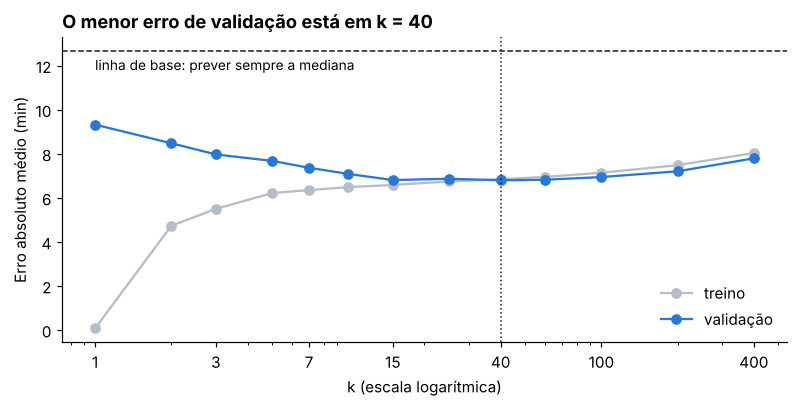

In [8]:
from sklearn.metrics import mean_absolute_error

X_treino, X_validacao, X_teste = treino[dois], validacao[dois], teste[dois]
t_treino, t_validacao, t_teste = treino["tempo_min"], validacao["tempo_min"], teste["tempo_min"]

valores_k = [1, 2, 3, 5, 7, 10, 15, 25, 40, 60, 100, 200, 400]
curva = []
for k in valores_k:
    modelo = make_pipeline(StandardScaler(), KNeighborsRegressor(k)).fit(X_treino, t_treino)
    curva.append({"k": k, "treino": mean_absolute_error(t_treino, modelo.predict(X_treino)), "validação": mean_absolute_error(t_validacao, modelo.predict(X_validacao))})
curva = pd.DataFrame(curva).set_index("k")
melhor_k = int(curva["validação"].idxmin())
linha_de_base = mean_absolute_error(t_validacao, np.full(len(t_validacao), t_treino.median()))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(curva.index, curva["treino"], "o-", color=CINZA, label="treino")
ax.plot(curva.index, curva["validação"], "o-", color=AZUL, label="validação")
ax.axhline(linha_de_base, color=TINTA, ls="--", lw=1)
ax.text(1, linha_de_base - 0.25, "linha de base: prever sempre a mediana", fontsize=9, va="top")
ax.axvline(melhor_k, color=TINTA, ls=":", lw=1)
ax.set_xscale("log")
ax.set_xticks([1, 3, 7, 15, 40, 100, 400], [1, 3, 7, 15, 40, 100, 400])
ax.set_xlabel("k (escala logarítmica)")
ax.set_ylabel("Erro absoluto médio (min)")
ax.set_title(f"O menor erro de validação está em k = {melhor_k}")
ax.legend(frameon=False, loc="lower right")
plt.show()

A leitura é a mesma do capítulo anterior, agora com um **erro** (quanto mais baixo, melhor): o erro de treino começa em zero com k = 1 e sobe sempre; o de validação desce, atinge um mínimo e volta a subir.

Com k = 1, o modelo tem erro zero no treino e é o pior de todos na validação. É o exemplo mais claro de que **o desempenho no treino não diz nada sobre o desempenho em dados novos**.

## Com mais atributos

Juntamos os restantes atributos, com a preparação do módulo 4, e comparamos na validação com a linha de base e com a regressão linear.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]
todas = numericas + nominais


def preparacao(colunas_numericas=numericas):
    return ColumnTransformer([("num", StandardScaler(), colunas_numericas), ("cat", OneHotEncoder(), nominais)])


def avaliar(modelo, dados=validacao):
    previsto = modelo.predict(dados[todas])
    return {"MAE": mean_absolute_error(dados["tempo_min"], previsto), "RMSE": np.sqrt(np.mean((dados["tempo_min"] - previsto) ** 2))}


candidatos = {"Regressão linear, todos os atributos": make_pipeline(preparacao(), LinearRegression()),
              f"KNN (k = {melhor_k}), distância e hora": make_pipeline(ColumnTransformer([("num", StandardScaler(), dois)]), KNeighborsRegressor(melhor_k)),
              f"KNN (k = {melhor_k}), todos os atributos": make_pipeline(preparacao(), KNeighborsRegressor(melhor_k)),
              f"KNN (k = {melhor_k}), todos exceto o peso": make_pipeline(preparacao([c for c in numericas if c != "peso_kg"]), KNeighborsRegressor(melhor_k)),
              f"KNN ponderado (k = {melhor_k}), todos exceto o peso": make_pipeline(preparacao([c for c in numericas if c != "peso_kg"]), KNeighborsRegressor(melhor_k, weights="distance"))}
linhas = {"Linha de base (mediana)": {"MAE": linha_de_base, "RMSE": np.sqrt(np.mean((t_validacao - t_treino.median()) ** 2))}}
for nome, modelo in candidatos.items():
    linhas[nome] = avaliar(modelo.fit(treino[todas], treino["tempo_min"]))
pd.DataFrame(linhas).T.round(2)

,MAE,RMSE
Linha de base (mediana),12.65,18.33
"Regressão linear, todos os atributos",6.50,11.48
"KNN (k = 40), distância e hora",6.79,12.04
"KNN (k = 40), todos os atributos",6.59,12.21
"KNN (k = 40), todos exceto o peso",6.54,12.10
"KNN ponderado (k = 40), todos exceto o peso",6.19,11.74


Para prever o **tempo**, ao contrário do que aconteceu com o atraso, as paragens, a chuva e o veículo trazem informação, e o KNN melhora um pouco quando os recebe. O peso continua a ser quase só ruído, e retirá-lo ajuda. A média ponderada dá aqui o melhor resultado, e é essa versão que escolhemos.

Repara que nenhum KNN bate claramente a regressão linear. Os dois ficam próximos no erro médio, mas erram em sítios diferentes: a regressão linear falha nas horas de ponta; o KNN capta-as melhor e é mais irregular onde há poucos dados. Os resíduos mostram a diferença.

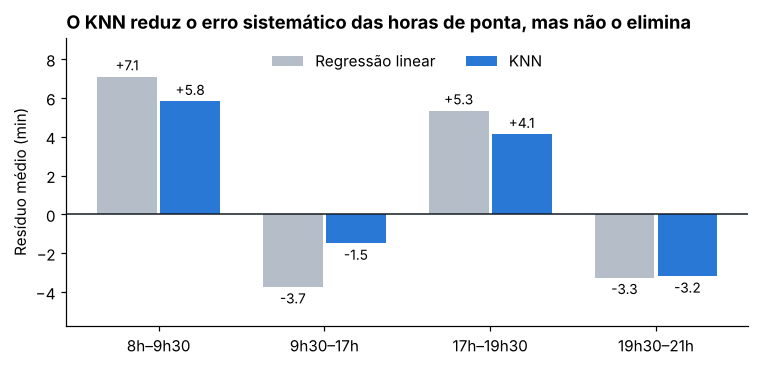

In [10]:
escolhido = candidatos[f"KNN ponderado (k = {melhor_k}), todos exceto o peso"]
periodos = pd.cut(validacao["hora"], [8, 9.5, 17, 19.5, 21], labels=["8h–9h30", "9h30–17h", "17h–19h30", "19h30–21h"], include_lowest=True)
sem_incidente = validacao["tempo_min"] < validacao["tempo_min"].quantile(0.985)
residuos = pd.DataFrame({"Regressão linear": validacao["tempo_min"] - candidatos["Regressão linear, todos os atributos"].predict(validacao[todas]),
                         "KNN": validacao["tempo_min"] - escolhido.predict(validacao[todas])})[sem_incidente]
media = residuos.groupby(periodos[sem_incidente], observed=True).mean()

fig, ax = plt.subplots(figsize=(8, 3.4))
posicoes = np.arange(len(media))
for i, (coluna, cor) in enumerate([("Regressão linear", CINZA), ("KNN", AZUL)]):
    barras = ax.bar(posicoes + (i - 0.5) * 0.38, media[coluna], 0.36, color=cor, label=coluna)
    ax.bar_label(barras, fmt="%+.1f", padding=2, fontsize=9)
ax.axhline(0, color=TINTA, lw=1)
ax.set_xticks(posicoes, media.index)
ax.set_ylim(media.min().min() - 2, media.max().max() + 2)
ax.set_ylabel("Resíduo médio (min)")
ax.set_title("O KNN reduz o erro sistemático das horas de ponta, mas não o elimina")
ax.legend(frameon=False, loc="upper center", ncol=2)
plt.show()

O KNN erra menos para o mesmo lado, mas o defeito não desapareceu. A razão está na forma de medir a semelhança: com seis atributos na distância, a hora é apenas um deles. Entre os 40 vizinhos de uma entrega das 18h há muitas entregas das 15h ou das 20h que são parecidas em tudo o resto, e que puxam a média para baixo. Para o KNN, «estar na hora de ponta» não é mais importante do que «ter duas paragens».

## Limite 1 – O KNN não extrapola

Um KNN só conhece os valores que viu. Para um ponto fora da zona dos dados, os vizinhos mais próximos são sempre os mesmos (os da fronteira), e a previsão deixa de mudar.

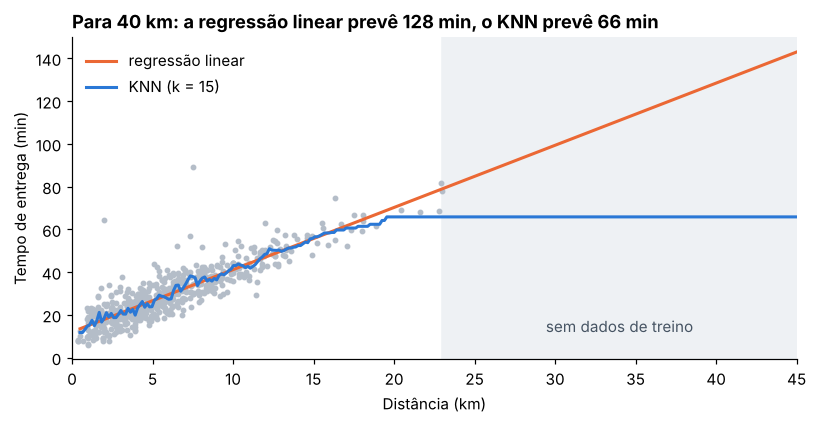

In [11]:
longe = np.linspace(0.5, 45, 300).reshape(-1, 1)
linear = LinearRegression().fit(X1, t)
knn = KNeighborsRegressor(15).fit(X1, t)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.scatter(x, t, s=8, color=CINZA)
ax.plot(longe, linear.predict(longe), color=LARANJA, lw=2, label="regressão linear")
ax.plot(longe, knn.predict(longe), color=AZUL, lw=2, label="KNN (k = 15)")
ax.axvspan(x.max(), 45, color="#eef1f4", zorder=0)
ax.text((x.max() + 45) / 2, 12, "sem dados de treino", ha="center", color="#465463")
ax.set_xlabel("Distância (km)")
ax.set_ylabel("Tempo de entrega (min)")
ax.set_xlim(0, 45)
ax.set_title(f"Para 40 km: a regressão linear prevê {linear.predict([[40]])[0]:.0f} min, o KNN prevê {knn.predict([[40]])[0]:.0f} min")
ax.legend(frameon=False, loc="upper left")
plt.show()

Depois do último ponto de treino, a previsão do KNN fica **horizontal**: para ele, uma entrega de 40 km demora o mesmo que as entregas mais longas que conhece. A regressão linear continua a tendência (o que também pode estar errado, mas pelo menos acompanha a direção).

Na prática: se a empresa abrir uma zona de entregas mais distante, ou se os preços subirem para valores nunca vistos, um KNN não acompanha. Antes de usar o modelo, vale a pena confirmar se os casos novos caem **dentro** da zona coberta pelos dados de treino.

## Limite 2 – A maldição da dimensionalidade

O KNN assenta numa hipótese: **os vizinhos mais próximos estão perto**. Com muitos atributos, isso deixa de ser verdade.

Um exemplo com contas simples. Imagina os dados espalhados uniformemente num cubo de lado 1. Para apanhar 1% dos dados numa vizinhança em forma de cubo, de que lado tem de ser essa vizinhança?

| Atributos | Lado necessário para conter 1% dos dados |
| --- | --- |
| 1 | 0,01 |
| 2 | 0,10 |
| 10 | 0,63 |
| 100 | 0,95 |

Com 10 atributos, a «vizinhança» tem de cobrir 63% da amplitude de **cada** atributo. Já não é vizinhança nenhuma. Vemos o mesmo a simular:

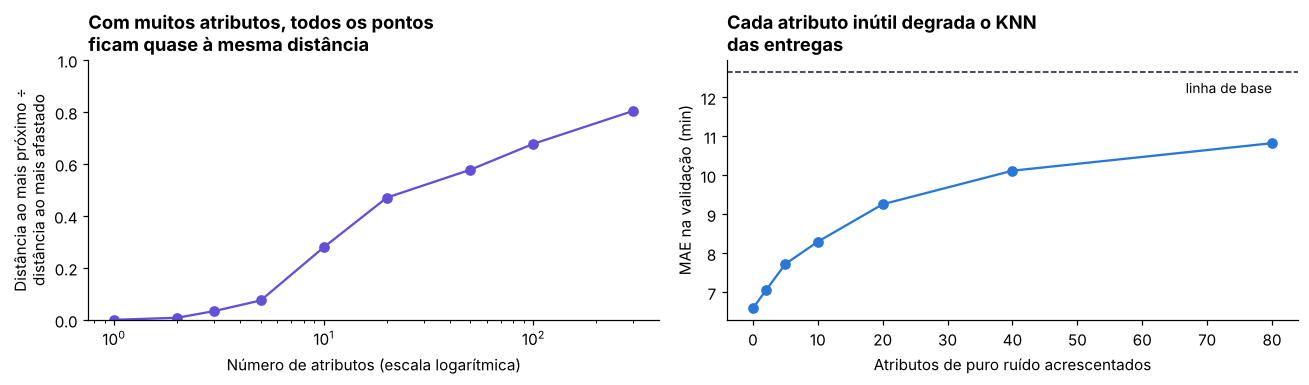

In [12]:
rng = np.random.default_rng(0)
dimensoes = [1, 2, 3, 5, 10, 20, 50, 100, 300]
razoes = []
for d in dimensoes:
    nuvem = rng.random((1000, d))
    distancias = np.sqrt(((nuvem[1:] - nuvem[0]) ** 2).sum(axis=1))
    razoes.append(distancias.min() / distancias.max())

transformador = preparacao().fit(treino[todas])
X_base, Xv_base = transformador.transform(treino[todas]), transformador.transform(validacao[todas])
extra = [0, 2, 5, 10, 20, 40, 80]
erros = []
for n in extra:
    ruido_treino, ruido_validacao = rng.normal(size=(len(treino), n)), rng.normal(size=(len(validacao), n))
    modelo = KNeighborsRegressor(melhor_k).fit(np.hstack([X_base, ruido_treino]), t_treino)
    erros.append(mean_absolute_error(t_validacao, modelo.predict(np.hstack([Xv_base, ruido_validacao]))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
ax1.plot(dimensoes, razoes, "o-", color=VIOLETA)
ax1.set_xscale("log")
ax1.set_ylim(0, 1)
ax1.set_xlabel("Número de atributos (escala logarítmica)")
ax1.set_ylabel("Distância ao mais próximo ÷\ndistância ao mais afastado")
ax1.set_title("Com muitos atributos, todos os pontos\nficam quase à mesma distância")
ax2.plot(extra, erros, "o-", color=AZUL)
ax2.axhline(linha_de_base, color=TINTA, ls="--", lw=1)
ax2.text(80, linha_de_base - 0.2, "linha de base", ha="right", va="top", fontsize=9)
ax2.set_xlabel("Atributos de puro ruído acrescentados")
ax2.set_ylabel("MAE na validação (min)")
ax2.set_title("Cada atributo inútil degrada o KNN\ndas entregas")
plt.tight_layout()
plt.show()

À esquerda, mil pontos ao acaso. Com um atributo, o ponto mais próximo está muitíssimo mais perto do que o mais afastado. Com centenas, a razão aproxima-se de 1: **o vizinho mais próximo está quase tão longe como o mais distante**, e «mais próximo» deixa de significar «parecido».

À direita, o efeito no nosso caso: acrescentando ao modelo das entregas colunas de números aleatórios, o erro sobe sem parar e aproxima-se do de não ter modelo.

O que fazer:

- **escolher os atributos** com critério, em vez de usar todos os disponíveis;
- **reduzir a dimensão** antes de aplicar o KNN (módulo 6);
- com muitos atributos, **preferir outro modelo**: as árvores do próximo capítulo escolhem sozinhas os atributos que usam.

## O teste

In [13]:
resultado = {"Linha de base (mediana)": {"MAE": mean_absolute_error(t_teste, np.full(len(t_teste), t_treino.median())), "RMSE": np.sqrt(np.mean((t_teste - t_treino.median()) ** 2))},
             "Regressão linear": avaliar(candidatos["Regressão linear, todos os atributos"], teste),
             f"KNN ponderado (k = {melhor_k}), todos exceto o peso": avaliar(escolhido, teste)}
pd.DataFrame(resultado).T.round(2)

,MAE,RMSE
Linha de base (mediana),13.01,20.64
Regressão linear,6.80,12.33
"KNN ponderado (k = 40), todos exceto o peso",6.57,12.84


No teste, o KNN e a regressão linear ficam de novo próximos, ambos com cerca de metade do erro da linha de base. O KNN reduziu o defeito das horas de ponta, sem o eliminar, e tem previsões mais irregulares onde há poucos vizinhos. Um modelo mais flexível não é automaticamente melhor. No próximo capítulo veremos um modelo que capta as horas de ponta de outra maneira.

## Exercícios

### `Exercício 1` – À mão

Os três vizinhos mais próximos de uma entrega nova estão às distâncias 0,2, 0,4 e 1,0 e demoraram 20, 26 e 50 minutos. Calcula a previsão com a média simples e com a média ponderada pelo inverso da distância.

<details>
<summary><b>Ver uma solução possível</b></summary>

- Média simples: (20 + 26 + 50) ÷ 3 = **32,0 min**.
- Pesos: 1 ÷ 0,2 = 5; 1 ÷ 0,4 = 2,5; 1 ÷ 1,0 = 1. Soma = 8,5.
- Média ponderada: (5 × 20 + 2,5 × 26 + 1 × 50) ÷ 8,5 = 215 ÷ 8,5 = **25,3 min**.

A ponderada fica mais perto dos dois vizinhos próximos e dá pouca importância ao terceiro, que está longe e tem um valor muito diferente.

</details>

### `Exercício 2` – A mediana dos vizinhos

As entregas com incidentes (tempos enormes) puxam a média dos vizinhos para cima. Escreve uma variante de `knn_regressao_um` que use a **mediana** dos vizinhos e compara o MAE e o RMSE na validação com os da média, usando a distância e a hora normalizadas (os arrays `A` e `B`) e k = 25.

In [14]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def knn_resumo(x_novo, X, y, k, resumo):
    return resumo(y[np.argsort(np.sqrt(((X - x_novo) ** 2).sum(axis=1)))[:k]])


for nome, resumo in [("média", np.mean), ("mediana", np.median)]:
    previsto = np.array([knn_resumo(b, A, alvo, 25, resumo) for b in B])
    print(f"{nome}: MAE {np.abs(t_validacao - previsto).mean():.2f} | RMSE {np.sqrt(np.mean((t_validacao - previsto) ** 2)):.2f}")
```

A mediana dá um MAE um pouco mais baixo: ignora os incidentes entre os vizinhos e prevê o tempo típico. O RMSE quase não muda, porque é dominado pelos próprios incidentes, que nenhuma das versões consegue prever. É a ligação do capítulo 1: a mediana está para o MAE como a média para o MSE.

</details>

### `Exercício 3` – Escolher k para a versão ponderada

Repete a curva de validação com `weights="distance"`, usando todos os atributos exceto o peso. O melhor k é o mesmo? O que acontece ao erro de **treino**, e porquê?

In [15]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
sem_peso = [c for c in numericas if c != "peso_kg"]
for k in [3, 7, 15, 25, 40, 60, 100]:
    m = make_pipeline(preparacao(sem_peso), KNeighborsRegressor(k, weights="distance")).fit(treino[todas], t_treino)
    print(f"k = {k:>3}: treino {mean_absolute_error(t_treino, m.predict(treino[todas])):.2f} | validação {mean_absolute_error(t_validacao, m.predict(validacao[todas])):.2f}")
```

O erro de treino é zero para qualquer k: cada ponto de treino está à distância zero de si próprio e recebe um peso praticamente infinito. Com a ponderação, o erro de treino deixa de dar qualquer informação. O melhor k na validação fica perto de 15, abaixo do que escolhemos com dois atributos: o melhor k depende dos atributos e da forma de fazer a média, e deve ser procurado de novo quando eles mudam.

</details>

### `Exercício 4` – Dentro ou fora dos dados?

A empresa quer usar o modelo para uma entrega de 32 km às 12h. Verifica quantas entregas de treino têm mais de 20 km e calcula a distância (em km) da entrega nova ao seu vizinho mais próximo no atributo `distancia_km`. Confiarias na previsão?

In [16]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
print("Entregas de treino com mais de 20 km:", int((treino["distancia_km"] > 20).sum()), "| máximo:", treino["distancia_km"].max())
print("Distância ao vizinho mais próximo:", round(float((32 - treino["distancia_km"]).abs().min()), 1), "km")
```

Há muito poucas entregas acima dos 20 km e nenhuma acima dos 25. A entrega nova está a vários quilómetros do caso mais parecido, fora da zona coberta pelos dados. O KNN dar-lhe-ia o tempo das entregas mais longas que conhece, quase de certeza abaixo do real. Não é uma previsão em que se deva confiar, e o modelo não avisa: devolve um número com o mesmo aspeto dos outros.

</details>

## Verifica o que aprendeste

- [ ] Sei o que muda do KNN de classificação para o de regressão.
- [ ] Sei calcular uma média ponderada pelo inverso da distância.
- [ ] Sei implementar o KNN de regressão em NumPy.
- [ ] Sei descrever a curva de previsão com k pequeno e com k grande.
- [ ] Sei escolher k pelo erro de validação.
- [ ] Sei porque um KNN não extrapola.
- [ ] Sei explicar a maldição da dimensionalidade.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/neighbors.html#nearest-neighbors-regression
- https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html
- https://en.wikipedia.org/wiki/Curse_of_dimensionality